# Extended Data Fig. 1: the three criticality measures (methods)

Top: d2 (2024 Euclidean) on real data, a → b → c following the computation (data → AR kernel → distance to the β = 2 plane, the distance histogram as inset of c), d the spectrum. Bottom: the method illustrations e, f.

- **a–d** from `analysis_scripts/revision/r38_hyperplane_explainer.py`: PPP20_day5, every non-overlapping 30 s NREM window (427), AR(20), signed distance to the plane and the two in-plane principal coordinates (`r38_hyperplane_windows.csv`).
- **e, f** from Extended Data Fig. 1a of the first submission, recoloured to match a–d.

In [1]:
# Data: ../csv/FigS1_AF_methods/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'FigS1_AF_methods'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

## a–d: d2 on real data

saved figure_output\supplementary\FigS1\FigS1_A_population_activity.svg / .png


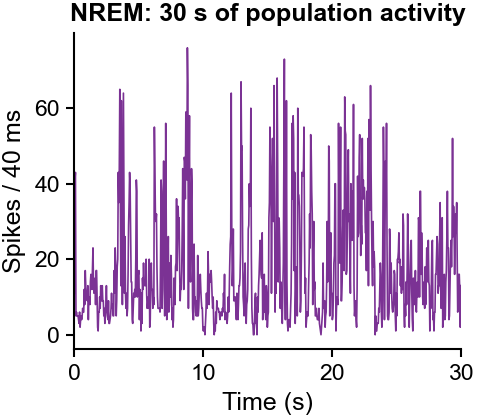

saved figure_output\supplementary\FigS1\FigS1_B_ar_kernel.svg / .png


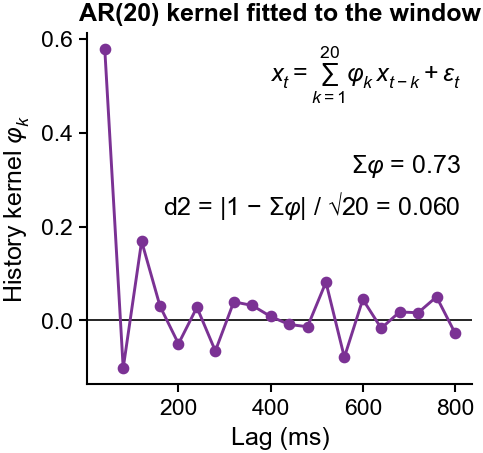

saved figure_output\supplementary\FigS1\FigS1_C_kernel_space_distance.svg / .png


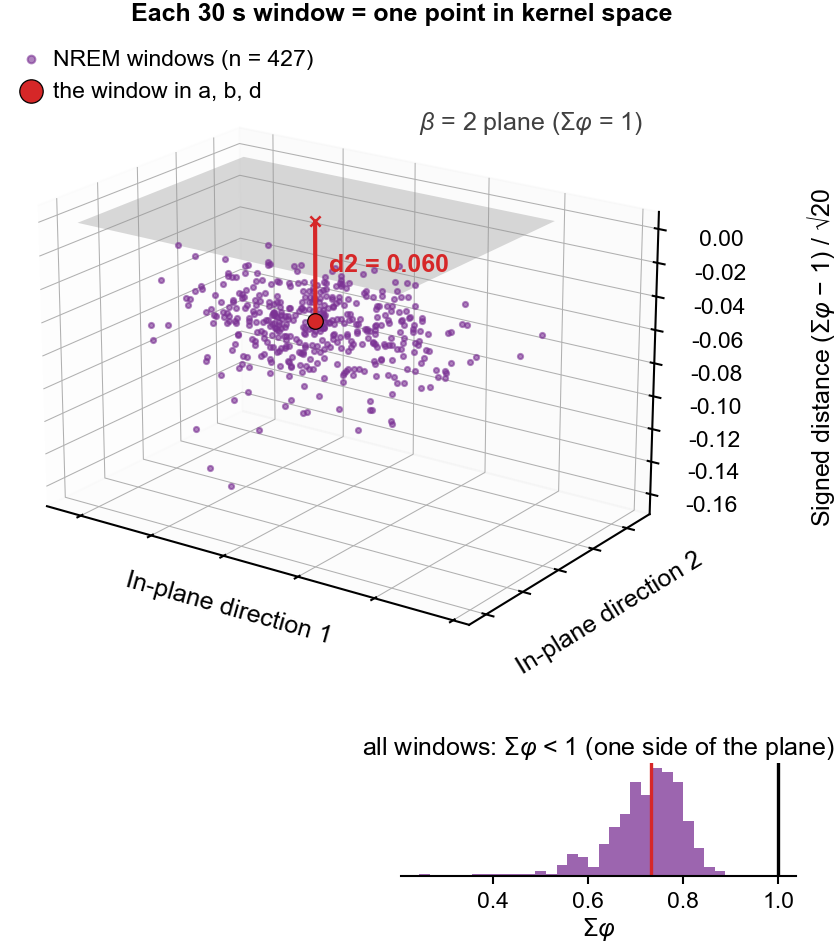

saved figure_output\supplementary\FigS1\FigS1_D_spectrum_beta2.svg / .png


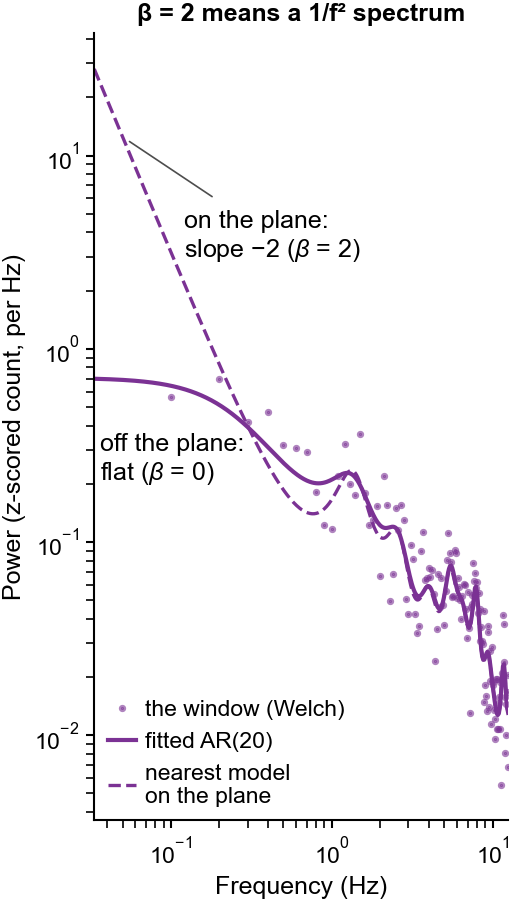

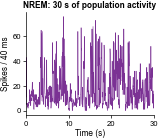

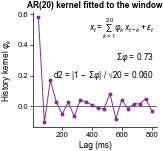

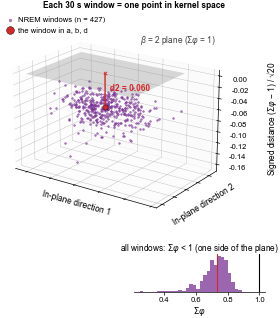

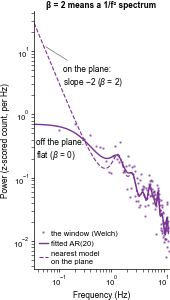

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
import r38_hyperplane_explainer_drawing as R      # r38_hyperplane_explainer.py's model_psd and constants (copied)
R.LOG = str(CSV)                                  # its table: this notebook's csv folder
from r38_hyperplane_explainer_drawing import DT, P   # 40 ms bins, AR order 20
pass  # (the session list: only for loading the example's spikes, below)

# The data of r38_hyperplane_explainer.py: every non-overlapping 30 s NREM window of PPP20_day5,
# AR(20) refitted by its published recipe (matching the stored d2), with its signed distance u and
# the two in-plane principal coordinates x, y -> data/revision/log/r38_hyperplane_windows.csv. Only the example window
# is refitted here (a, b, d), with the producer's own functions.
D = pd.read_csv(os.path.join(R.LOG, "r38_hyperplane_windows.csv"))
D = D[D.state == "NREM"].reset_index(drop=True)
g = D[np.abs(D.d2_refit - D.d2_stored) < 1e-6]                       # the producer's example rule
c = D[["x", "y", "u"]]
i = int((((g[["x", "y", "u"]] - c.median()) / (c.quantile(0.75) - c.quantile(0.25))) ** 2).sum(1).idxmin())
ex = D.loc[i]
# ---- data (../csv) ----
# the example window (PPP20 day 5, centre in r38_hyperplane_windows.csv): its 40 ms population counts (all CA1
# units, from the recording) and its AR(20) fit (r38_hyperplane_explainer.yw_kernel)
x = read_csv('figs1_example_window_counts_40ms.csv')['count'].to_numpy()
phi = read_csv('figs1_example_kernel.csv').phi.to_numpy()
s2 = float(read_csv('figs1_example_s2.csv').s2[0])
# ---- the same from the recordings, with analysis_scripts/: ----
# from neuro_py.io import loading
# bp = next(b for b in FIG1_SESSIONS if "_".join(session_id(b)) == R.EX)
# st, cm = loading.load_spikes(bp, brainRegion="CA1")                  # reads W: (read-only)
# sp = np.sort(np.concatenate([np.asarray(u_, float) for u_ in np.asarray(st.data, dtype=object)]))   # all CA1 units
# x = getFR(sp, ex.center_s - R.WIN / 2, ex.center_s + R.WIN / 2)
# phi, s2 = R.yw_kernel(x)
# assert abs(phi.sum() - ex.sum_phi) < 1e-9 and abs(s2 - ex.s2) < 1e-9, "example refit differs from the table"
NREM, RED = R.COL["NREM"], R.RED

F.final_style()
TITLE = dict(fontweight="bold", fontsize=6)          # a short bold title above each of a-d
# ---- a: the data, one 30 s NREM window
fig, ax = plt.subplots(figsize=(42 * F.MM, 37 * F.MM), layout="constrained")
ax.plot(np.arange(x.size) * DT, x, color=NREM, lw=0.4)
ax.set_xlim(0, R.WIN); ax.set_xlabel("Time (s)"); ax.set_ylabel("Spikes / 40 ms")
ax.set_title("NREM: 30 s of population activity", **TITLE)
F.show(F.save(fig, "FigS1_A_population_activity"))

# ---- b: what is fitted, the AR(20) history kernel
fig, ax = plt.subplots(figsize=(42 * F.MM, 40 * F.MM), layout="constrained")
lags = 1000 * DT * np.arange(1, P + 1)
ax.axhline(0, color="k", lw=0.4)
ax.plot(lags, phi, "o-", ms=1.8, lw=0.7, color=NREM)
ax.set_xlabel("Lag (ms)"); ax.set_ylabel(r"History kernel $\varphi_k$")
ax.set_title("AR(20) kernel fitted to the window", **TITLE)
ax.text(0.97, 0.97, r"$x_t = \sum_{k=1}^{20}\varphi_k\,x_{t-k} + \varepsilon_t$", transform=ax.transAxes, ha="right", va="top")
ax.text(0.97, 0.66, rf"$\Sigma\varphi$ = {phi.sum():.2f}" + "\n" + rf"d2 = |1 − $\Sigma\varphi$| / √20 = {ex.d2_refit:.3f}",   # √ written as text
        transform=ax.transAxes, ha="right", va="top", linespacing=1.4)
F.show(F.save(fig, "FigS1_B_ar_kernel"))

# ---- c: each window = one point in the 20-lag kernel space; d2 = its distance to the beta = 2 plane
fig = plt.figure(figsize=(76 * F.MM, 80 * F.MM))
fig.text(0.5, 0.995, "Each 30 s window = one point in kernel space", ha="center", va="top", **TITLE)
ax = fig.add_axes([0.0, 0.25, 0.86, 0.71], projection="3d", computed_zorder=False)   # room on the right for the z label
lim = np.percentile(np.abs(np.r_[D.x, D.y]), 99) * 1.1
gx, gy = np.meshgrid(np.linspace(-lim, lim, 2), np.linspace(-lim, lim, 2))
ax.plot_surface(gx, gy, 0 * gx, color="#bdbdbd", alpha=0.35, lw=0)
ax.set_box_aspect((2.0, 1.3, 1.25))
ax.scatter(D.x, D.y, D.u, s=1.5, color=NREM, alpha=0.6, depthshade=False, zorder=1, label=f"NREM windows (n = {len(D)})")
ax.plot([ex.x] * 2, [ex.y] * 2, [ex.u, 0], color=RED, lw=1.0, zorder=9)
ax.scatter([ex.x], [ex.y], [0], s=6, color=RED, marker="x", lw=0.6, depthshade=False, zorder=9)
ax.scatter([ex.x], [ex.y], [ex.u], s=14, color=RED, edgecolor="k", lw=0.3, depthshade=False, zorder=10, label="the window in a, b, d")
ax.text(ex.x, ex.y, ex.u / 2, f"  d2 = {ex.d2_refit:.3f}", color=RED, fontweight="bold", zorder=11)
ax.text2D(0.62, 0.86, r"$\beta$ = 2 plane ($\Sigma\varphi$ = 1)", transform=ax.transAxes, color="0.25")
ax.set_zlim(D.u.min() * 1.05, 0.01)
ax.set_xlabel("In-plane direction 1", labelpad=-12); ax.set_ylabel("In-plane direction 2", labelpad=-12)
ax.set_zlabel("")                                     # a 2-D label is used instead (below)
fig.text(0.985, 0.62, r"Signed distance ($\Sigma\varphi$ − 1) / √20", rotation=90, ha="right", va="center")
ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(axis="z", pad=0.5)
for a_ in (ax.xaxis, ax.yaxis, ax.zaxis):
    a_.pane.set_alpha(0.15); a_._axinfo["grid"]["linewidth"] = 0.25
ax.view_init(elev=20, azim=-55)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 1.0), markerscale=1.5)
ins = fig.add_axes([0.50, 0.07, 0.44, 0.12])          # the distance axis of the cloud, as a distribution
bins = np.linspace(D.sum_phi.min() - 0.02, 1.0, 35)
ins.hist(D.sum_phi, bins=bins, color=NREM, alpha=0.75)
ins.axvline(1, color="k", lw=0.8); ins.axvline(ex.sum_phi, color=RED, lw=0.8)
ins.set_xlabel(r"$\Sigma\varphi$", labelpad=1)
ins.set_title(r"all windows: $\Sigma\varphi$ < 1 (one side of the plane)", pad=2)
ins.set_yticks([]); ins.spines["left"].set_visible(False)
ins.set_xticks([0.4, 0.6, 0.8, 1.0])
F.show(F.save(fig, "FigS1_C_kernel_space_distance"))

# ---- d: why "beta = 2": the model on the plane rises as 1/f^2 at low frequency, the fitted model flattens
fig, ax = plt.subplots(figsize=(45 * F.MM, 78 * F.MM), layout="constrained")
f = np.logspace(np.log10(1 / R.WIN), np.log10(0.5 / DT), 400)            # window length .. Nyquist (12.5 Hz)
z = (x - x.mean()) / x.std(ddof=1)
fw, pw = welch(z, fs=1 / DT, nperseg=250)
on = phi + (1 - phi.sum()) / P                                           # the kernel moved perpendicularly onto the plane
ax.loglog(fw[1:], pw[1:], ".", ms=1.5, color=NREM, alpha=0.6, label="the window (Welch)")
ax.loglog(f, R.model_psd(phi, s2, f), "-", color=NREM, lw=1.0, label="fitted AR(20)")
ax.loglog(f, R.model_psd(on, s2, f), "--", color=NREM, lw=0.8, label="nearest model\non the plane")
fa = 0.05
ax.annotate("on the plane:\nslope $-$2 ($\\beta$ = 2)", xy=(fa, R.model_psd(on, s2, np.array([fa]))[0]),
            xytext=(0.12, 3), arrowprops=dict(arrowstyle="-", color="0.3", lw=0.4))
ax.text(0.036, R.model_psd(phi, s2, np.array([0.036]))[0] * 0.3, "off the plane:\nflat ($\\beta$ = 0)")
ax.set_xlim(1 / R.WIN, 0.5 / DT)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (z-scored count, per Hz)")
ax.set_title("β = 2 means a 1/f² spectrum", **TITLE)
ax.legend(loc="lower left")
F.show(F.save(fig, "FigS1_D_spectrum_beta2"))

## e, f: Methods 2 and 3 (from Extended Data Fig. 1a)

cropped Extended Data Fig1.svg [2.5, 4.5, 121.0 x 57.0] -> figure_output\supplementary\FigS1\FigS1_EF_methods_avalanche_branching.svg (121.0 x 57.0 mm)


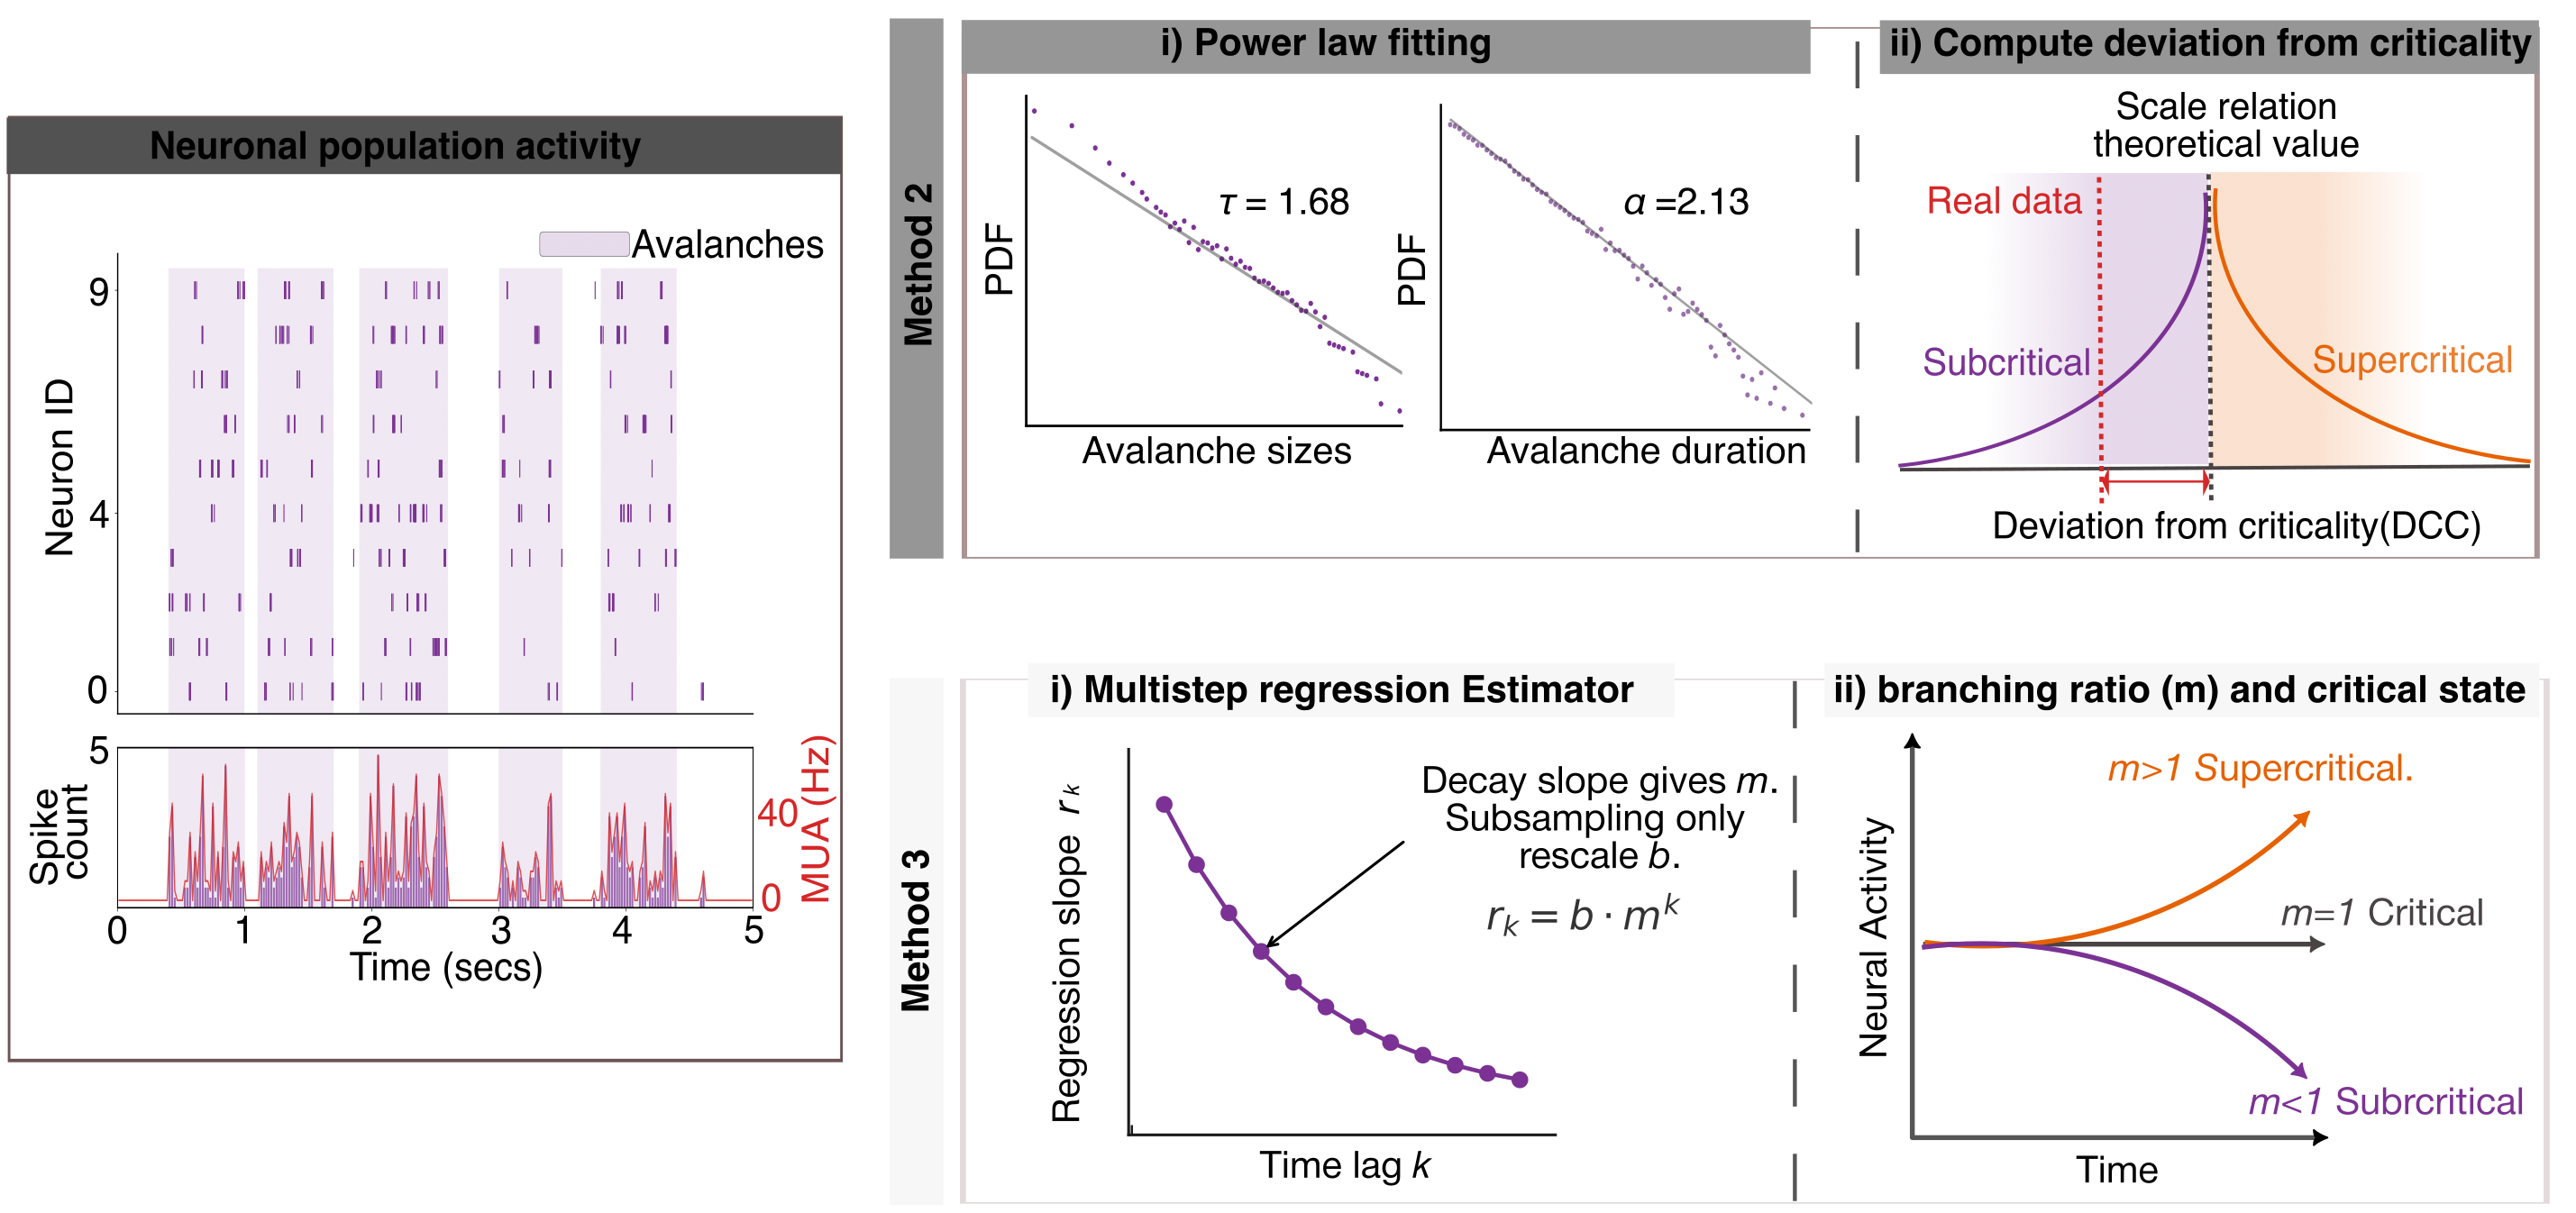

In [3]:
# Methods 2 and 3: Extended Data Fig. 1a (reports/new_planc/nature/Extended Data Fig1.svg) -- population activity
# with avalanches, Method 2 (avalanche power laws -> DCC), Method 3 (MR estimator -> branching ratio). Its units are
# mm; region measured on its 400-dpi render (ink x 3-122.2, y 5.3-61.1; panel b's label starts at x 124.5); its
# letter "a" is left out (the assembler draws e and f).
# ---- data (../csv) ----
ED1 = str(CSV / "assets" / "Extended Data Fig1.svg")   # the submitted Extended Data Fig. 1
# ---- the same from the recordings, with analysis_scripts/: ----
# ED1 = os.path.join(F.REPO, "reports", "new_planc", "nature", "Extended Data Fig1.svg")
METHODS = (2.5, 4.5, 121.0, 57.0)
EF = F.crop_svg(ED1, "FigS1_EF_methods_avalanche_branching", *METHODS, drop_ids=["text225064"], unit_mm=1.0)

# e and f recoloured to match a-d: NREM purple for the data, a-d's red for MUA and "Real data"; sub- / supercritical
# as a purple-orange diverging pair (PuOr) in both methods -- subcritical purple (the side the data lie on),
# supercritical orange, critical dark grey. Only elements of e and f are touched, by their position in the figure.
PURPLE, PURPLE_MID, LAVENDER, RED_AD, GREY_FIT, ORANGE = "#7b3294", "#9970ab", "#c2a5cf", "#d62728", "#404040", "#e66101"
Q = F.svg_bboxes(ED1)                                           # mm


def ids_in(x0, x1, y0, y1):
    return {i for i, (x, y, w, h) in Q.items() if x0 <= x + w / 2 < x1 and y0 <= y + h / 2 < y1}


RASTER, POWERLAW, METHOD2 = ids_in(2.5, 44, 4.5, 61.5), ids_in(44, 86, 4.5, 36.5), ids_in(44, 123.5, 4.5, 36.5)
DCC = ids_in(86, 123.5, 4.5, 36.5) | {"stop166", "stop168", "stop170", "stop172", "stop202", "stop204", "stop206", "stop208"}
METHOD3 = ids_in(44, 123.5, 36.5, 61.5)                        # f
NEURONS = ["#f1c40f", "#9b59b6", "#1abc9c", "#f39c12", "#e91e63", "#2ecc71", "#e67e22", "#e74c3c", "#3498db", "#34495e"]
SHADE = ["#ff687c", "#ff6b6b", "#4ecdc4", "#45b7d1", "#96ceb4", "#ffeaa7"]          # avalanche shading (fill / outlines)
done = F.recolor_svg(EF, [
    (RASTER, {**{c: PURPLE for c in NEURONS}, **{c: LAVENDER for c in SHADE},
              "#00008b": PURPLE, "#ff0000": RED_AD}),                 # spikes, avalanches, count bars, MUA
    (POWERLAW, {"#1f77b4": PURPLE, "#ff7e0e": GREY_FIT, "#dd8452": GREY_FIT}),   # size points, fit lines
    (METHOD2, {"#2ca02c": PURPLE_MID}),                               # duration points
    (DCC, {"#1f77b4": PURPLE, "#ff7f0e": ORANGE, "#d72828": RED_AD}),   # subcritical, supercritical (curves, text, shading)
    (METHOD3, {"#e69f00": PURPLE, "#1f77b4": PURPLE, "#ff7f0e": ORANGE}),   # r_k decay; m < 1, m > 1
])
F.show(F.stem("FigS1_EF_methods_avalanche_branching") + ".png")

## c, d with the β = 4 manifold

c and d redrawn with the β = 4 manifold beside β = 2, as separate panel files. Following the 2024 method (`euclid_order_sweep._manifold_basis` / `euclid_db`), a kernel lies on the β manifold when 1 − Σφ_k z^k has a root at z = 1 of order β/2: β = 2 is the plane Σφ = 1; β = 4 adds Σ kφ_k = 0, a line inside that plane.

- c: z = signed distance to the β = 2 plane; x = the in-plane direction normal to the β = 4 set, so d4 = √(x² + z²); y = the largest remaining in-plane variation.
- d: the nearest model on β = 2 (1/f²) and on β = 4 (1/f⁴), and the fitted AR(20) of the window.
- Output: `FigS1_C_kernel_space_beta2_beta4`, `FigS1_D_spectrum_beta2_beta4`, `FigS1_assembled_v2`.

saved figure_output\supplementary\FigS1\FigS1_C_kernel_space_beta2_beta4.svg / .png


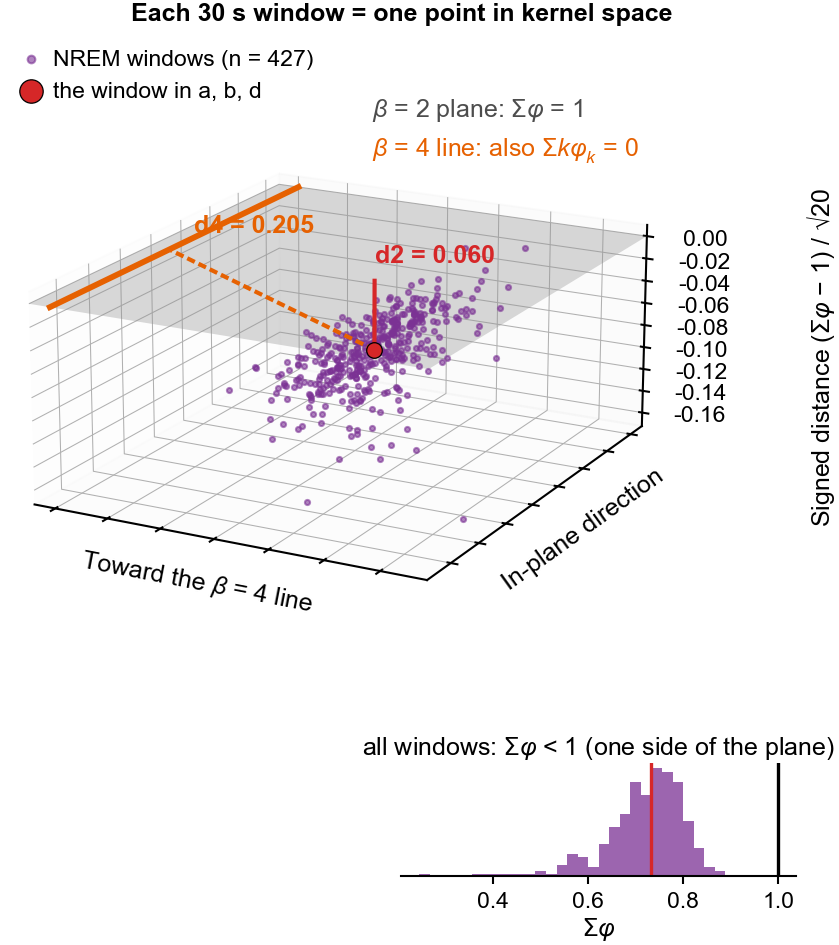

saved figure_output\supplementary\FigS1\FigS1_D_spectrum_beta2_beta4.svg / .png


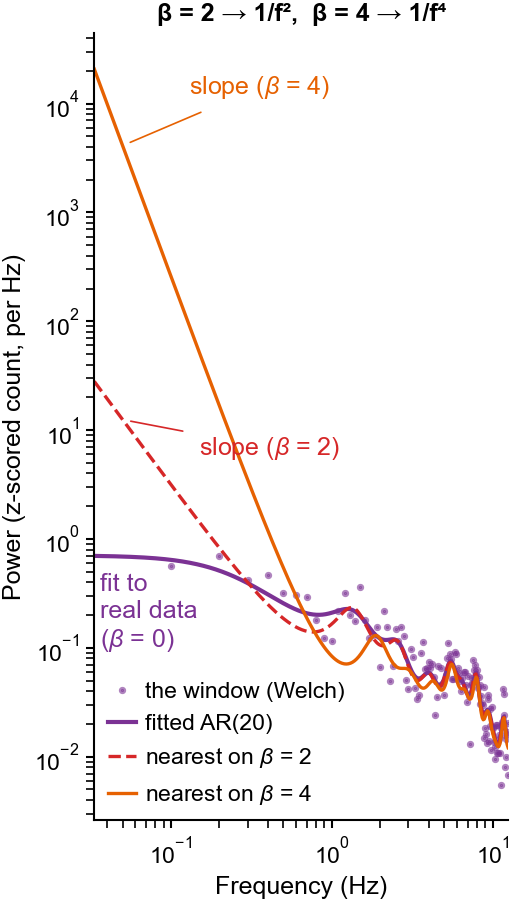

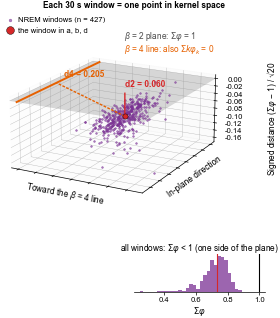

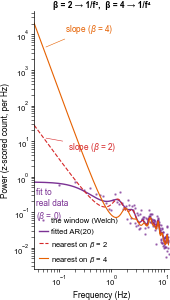

In [4]:
# c, d extended with the beta = 4 manifold.
# The beta manifolds follow the authors' 2024 method (ported to Python as euclid_order_sweep._manifold_basis /
# euclid_db): kernels whose 1 - sum_k phi_k z^k has a root at z = 1 of
# order beta/2. beta = 2: sum phi = 1 (a plane); beta = 4: also sum k phi_k = 0 -- a line inside that plane in the picture.
# Axes, exact: z = signed distance to the beta = 2 plane; x = the in-plane direction normal to the beta = 4
# set, so d4 = sqrt(x^2 + z^2) exactly; y = the largest remaining in-plane variation. Drawn to scale (isometric box).
from euclid_order_sweep_drawing import euclid_db, _manifold_basis   # euclid_order_sweep.py's (copied)
from r38_hyperplane_explainer_drawing import P as P_AR      # the AR order

# ---- data (../csv) ----
K = read_csv('figs1_window_kernels.csv').filter(like='phi').to_numpy()   # every window's AR(20) kernel (yw_kernel on its counts)
# ---- the same from the recordings, with analysis_scripts/: ----
# K = np.array([R.yw_kernel(getFR(sp, c_ - R.WIN / 2, c_ + R.WIN / 2))[0] for c_ in D.center_s])   # every window's kernel
assert np.abs(K.sum(1) - D.sum_phi).max() < 1e-9, "refit differs from the table"
k_ = np.arange(1, P_AR + 1)
n1 = np.ones(P_AR) / np.sqrt(P_AR)                                     # normal of the beta = 2 plane
n2 = (k_ - k_.mean()); n2 = n2 / np.linalg.norm(n2)                # in-plane normal of the beta = 4 set
phi4 = _manifold_basis(P_AR, 4)[:, 0]                                 # a point on beta = 4: [2, -1, 0, ...]
Z, X = (K - phi4) @ n1, (K - phi4) @ n2
Rr = (K - phi4) - np.outer(Z, n1) - np.outer(X, n2)
Rc = Rr - Rr.mean(0)
Y = Rc @ np.linalg.svd(Rc, full_matrices=False)[2][0]
d4 = np.hypot(X, Z)
d4_port = np.array([euclid_db(kk, 4) for kk in K]); d2_port = np.array([euclid_db(kk, 2) for kk in K])
assert np.abs(d4 - d4_port).max() < 1e-6 and np.abs(d2_port - D.d2_refit).max() < 1e-6, "geometry differs from the authors' code"
on2 = K[i] + (1 - K[i].sum()) / P_AR                                  # nearest model on beta = 2 (as above)
_x0, _X = _manifold_basis(P_AR, 4)[:, 0], (_manifold_basis(P_AR, 4) - _manifold_basis(P_AR, 4)[:, [0]])[:, 1:]
on4 = _x0 + _X @ np.linalg.lstsq(_X, K[i] - _x0, rcond=None)[0]    # nearest model on beta = 4 (the authors' projection)
assert abs(np.linalg.norm(K[i] - on4) - d4[i]) < 1e-6
C4 = "#e66101"                                                      # beta = 4 (line in c, model in d)

# ---- c: kernel space with the beta = 2 plane and the beta = 4 line, both distances of the example
fig = plt.figure(figsize=(76 * F.MM, 80 * F.MM))
fig.text(0.5, 0.995, "Each 30 s window = one point in kernel space", ha="center", va="top", **TITLE)
ax = fig.add_axes([0.0, 0.25, 0.86, 0.71], projection="3d", computed_zorder=False)
xr = (-0.02, X.max() * 1.08); yr = (np.percentile(Y, 1) * 1.15, np.percentile(Y, 99) * 1.15); zr = (Z.min() * 1.05, 0.01)
gx, gy = np.meshgrid(np.linspace(*xr, 2), np.linspace(*yr, 2))
ax.plot_surface(gx, gy, 0 * gx, color="#bdbdbd", alpha=0.35, lw=0)
ax.plot([0, 0], yr, [0, 0], color=C4, lw=1.4, zorder=8)                          # the beta = 4 line
ax.set_box_aspect((xr[1] - xr[0], yr[1] - yr[0], zr[1] - zr[0]))                 # to scale: lengths comparable
ax.scatter(X, Y, Z, s=1.5, color=NREM, alpha=0.6, depthshade=False, zorder=1, label=f"NREM windows (n = {len(D)})")
ax.plot([X[i]] * 2, [Y[i]] * 2, [Z[i], 0], color=RED, lw=1.0, zorder=9)          # d2: to the plane
ax.plot([X[i], 0], [Y[i]] * 2, [Z[i], 0], color=C4, lw=1.0, ls=(0, (2, 1)), zorder=9)   # d4: to the line
ax.scatter([X[i]], [Y[i]], [Z[i]], s=14, color=RED, edgecolor="k", lw=0.3, depthshade=False, zorder=10, label="the window in a, b, d")
ax.text(X[i], Y[i], 0.012, f"d2 = {D.d2_refit[i]:.3f}", color=RED, fontweight="bold", ha="left", va="bottom", zorder=11)   # above the plane: clear of the cloud
ax.text(X[i] * 0.42, Y[i], 0.022, f"d4 = {d4[i]:.3f}", color=C4, fontweight="bold", ha="center", va="bottom", zorder=11)   # above the plane, by the line
ax.text2D(0.55, 0.88, r"$\beta$ = 2 plane: $\Sigma\varphi$ = 1", transform=ax.transAxes, color="0.3")
ax.text2D(0.55, 0.82, r"$\beta$ = 4 line: also $\Sigma k\varphi_k$ = 0", transform=ax.transAxes, color=C4)
ax.set_xlim(*xr); ax.set_ylim(*yr); ax.set_zlim(*zr)
ax.set_xlabel(r"Toward the $\beta$ = 4 line", labelpad=-12); ax.set_ylabel("In-plane direction", labelpad=-12)
ax.set_zlabel("")
fig.text(0.985, 0.62, r"Signed distance ($\Sigma\varphi$ − 1) / √20", rotation=90, ha="right", va="center")
ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(axis="z", pad=0.5)
for a_ in (ax.xaxis, ax.yaxis, ax.zaxis):
    a_.pane.set_alpha(0.15); a_._axinfo["grid"]["linewidth"] = 0.25
ax.view_init(elev=18, azim=-62)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 1.0), markerscale=1.5)
ins = fig.add_axes([0.50, 0.07, 0.44, 0.12])           # the distance axis of the cloud (as above)
bins = np.linspace(D.sum_phi.min() - 0.02, 1.0, 35)
ins.hist(D.sum_phi, bins=bins, color=NREM, alpha=0.75)
ins.axvline(1, color="k", lw=0.8); ins.axvline(ex.sum_phi, color=RED, lw=0.8)
ins.set_xlabel(r"$\Sigma\varphi$", labelpad=1)
ins.set_title(r"all windows: $\Sigma\varphi$ < 1 (one side of the plane)", pad=2)
ins.set_yticks([]); ins.spines["left"].set_visible(False)
ins.set_xticks([0.4, 0.6, 0.8, 1.0])
F.show(F.save(fig, "FigS1_C_kernel_space_beta2_beta4"))

# ---- d: the nearest model on each manifold -- 1/f^2 on beta = 2, 1/f^4 on beta = 4
fig, ax = plt.subplots(figsize=(45 * F.MM, 78 * F.MM), layout="constrained")
f = np.logspace(np.log10(1 / R.WIN), np.log10(0.5 / DT), 400)
z = (x - x.mean()) / x.std(ddof=1)
fw, pw = welch(z, fs=1 / DT, nperseg=250)
ax.loglog(fw[1:], pw[1:], ".", ms=1.5, color=NREM, alpha=0.6, label="the window (Welch)")
ax.loglog(f, R.model_psd(phi, s2, f), "-", color=NREM, lw=1.0, label="fitted AR(20)")
ax.loglog(f, R.model_psd(on2, s2, f), "--", color=RED, lw=0.8, label=r"nearest on $\beta$ = 2")   # red as d2 in c
ax.loglog(f, R.model_psd(on4, s2, f), "-", color=C4, lw=0.8, label=r"nearest on $\beta$ = 4")
fa = 0.05
ax.annotate("slope ($\\beta$ = 4)", xy=(fa, R.model_psd(on4, s2, np.array([fa]))[0]), xytext=(0.13, R.model_psd(on4, s2, np.array([fa]))[0] * 3),
            color=C4, arrowprops=dict(arrowstyle="-", color=C4, lw=0.4))
ax.annotate("slope ($\\beta$ = 2)", xy=(fa, R.model_psd(on2, s2, np.array([fa]))[0]), xytext=(0.15, 6),
            color=RED, arrowprops=dict(arrowstyle="-", color=RED, lw=0.4))
ax.text(0.036, R.model_psd(phi, s2, np.array([0.036]))[0] * 0.7, "fit to\nreal data\n($\\beta$ = 0)", color=NREM, va="top")   # labels and colours as c; the line is the AR(20) fit
ax.set_xlim(1 / R.WIN, 0.5 / DT)
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (z-scored count, per Hz)")
ax.set_title("β = 2 → 1/f²,  β = 4 → 1/f⁴", **TITLE)
ax.legend(loc="lower left")
F.show(F.save(fig, "FigS1_D_spectrum_beta2_beta4"))